# Commons

In [30]:
from __future__ import annotations

from pathlib import Path
import os

import numpy as np
import pandas as pd
import pydicom
import torch
from skimage.transform import resize
from torch.utils.data import DataLoader, Dataset

### Data functions ###


def ct_normalization(img, meta):
    """
    Normaliza el rango HU a [0, 1].
    Ajustamos de -1024 (aire) a 3072 (tejido denso) para cubrir un rango amplio
    para resaltar detalles anatómicos.
    """
    def scale(img, meta, slope=1.0, intersept=-1024):
        MIN_B = -1024
        MAX_B = 3072

        slope = float(meta.get("Rescale Slope", slope))
        intersept = float(meta.get("Rescale Intercept", intersept))
        
        img = np.asarray(img) * slope + intersept  # Aplica la transformación de escala y desplazamiento
        img = resize(img, (256, 256), preserve_range=True)  # Asegura que todas las imágenes tengan el mismo tamaño
        img = (img - MIN_B) / (MAX_B - MIN_B)  # Escala a [0, 1]
        if img.ndim == 2:
            img = np.expand_dims(img, axis=0)
        return img.astype(np.float32)
    
    return scale(img, meta)


def _read_dicom(path: Path) -> np.ndarray:
    
    ds = pydicom.dcmread(path)  # Lee el archivo DICOM y convierte a numpy array
    metadata = {}
    for element in ds:
            if getattr(element, "name", None) == "Pixel Data":
                continue
            try:
                name = str(element.name)
                value = element.value
                if value is None:
                    continue
                metadata[name] = str(value)
            except Exception:
                continue

    return ct_normalization(ds.pixel_array, metadata)

def save_tensor_cache(tensor, cache_path: Path) -> None:
        if cache_path is None:
            return
        cache_path.parent.mkdir(parents=True, exist_ok=True)
        tmp_path = cache_path.with_suffix(cache_path.suffix + ".tmp")
        torch.save(tensor, tmp_path)
        try:
            with open(tmp_path, "rb+") as handle:
                os.fsync(handle.fileno())
        except OSError:
            pass
        os.replace(tmp_path, cache_path)


class LDCTDataset(Dataset):
    def __init__(
        self,
        df: pd.DataFrame,
        dim: int = 2,
        model_type: str = "model",
    ) -> None:
        """
        Args:
            df: DataFrame with either:
                - dim == 2: columns ['Case', 'SDCT', 'LDCT'] where SDCT/LDCT are file paths to DICOM images
                - dim == 3: columns ['Case', 'SDCT', 'LDCT'] where SDCT/LDCT are volume directories
            transform: Optional transform to be applied on a sample.
            model_type: "model" or "vae", used to determine how to process the data.
        """
        self.dim = dim
        self.data = df.dropna()
        self.model_type = model_type
        self.cache_saving = False

        self._preprocess()

    def _preprocess(self) -> pd.DataFrame:
        rows = []

        unwrap_dir = lambda path: sorted([str(path / fname) for fname in os.listdir(path) if (path / fname).is_file()])

        idx = 0
        for row in self.data.itertuples(index=False):
            sdct_dir = Path(row.SDCT)
            sdct_files = unwrap_dir(sdct_dir)
            
            if self.model_type == "model":
                ldct_dir = Path(row.LDCT)
                ldct_files = unwrap_dir(ldct_dir)
                
                if self.dim == 3:
                    rows.append({
                        'Case': row.Case, 
                        'SDCT': sdct_files, 
                        'LDCT': ldct_files,
                        'split_count': len(ldct_files),
                        'split_idx': idx
                    })
                else:
                    rows.extend([
                        {'Case': row.Case, 'SDCT': s, 'LDCT': l, 'split_count': len(ldct_files), 'split_idx': idxS} 
                        for idxS, (s, l) in enumerate(zip(sdct_files, ldct_files))
                    ])
            
            elif self.model_type == "vae":
                if self.dim == 3:
                    rows.append({
                        'Case': row.Case, 
                        'SDCT': sdct_files,
                        'split_count': len(sdct_files),
                        'split_idx': idx
                    })
                else:
                    rows.extend([
                        {'Case': row.Case, 'SDCT': s, 'split_count': len(sdct_files), 'split_idx': idxS} 
                        for idxS, s in enumerate(sdct_files)
                    ])

            idx += 1
                    
        df = pd.DataFrame(rows)
        self.data = df.to_dict("records")
        self.size = len(self.data)
    
    def load_dicom(self, idx: int, modality: str = "SDCT") -> dict:
        row = self.data[idx]
        cache_path = "./cache/tensors"

        check_cache = lambda modality: True if Path(f"./cache/tensors/{self.data[idx]['Case']}_{modality}.pt").exists() else False

        if self.dim == 3:
            if check_cache(modality):
                cache_file = Path(f"./cache/tensors/{self.data[idx]['Case']}_{modality}.pt")
                return torch.load(cache_file)
            volume = np.array([_read_dicom(f) for f in sorted(row[modality])]) # Shape: (D, H, W)
            tensor = torch.as_tensor(volume).float().contiguous()  # Shape: (1, D, H, W)
            
            if self.cache_saving:
                save_tensor_cache(tensor, cache_path=Path(f"{cache_path}/{row['Case']}_{modality}").with_suffix('.pt'))
                
            return tensor
        else:
            if check_cache(modality):
                cache_file = Path(f"./cache/tensors/{self.data[idx]['Case']}_{modality}.pt")
                return torch.load(cache_file)
            img = _read_dicom(Path(row[modality]))
            tensor = torch.as_tensor(img).float().contiguous()  # Shape: (1, H, W)
            if self.cache_saving:
                save_tensor_cache(tensor, Path(f"{cache_path}/{row['split_idx']}_{row['Case']}_{modality}").with_suffix('.pt'))
            return tensor
    
    def __len__(self) -> int:
        return self.size

    def __getitem__(self, idx: int = None, case: str = None, split_idx: int = None) -> dict:
        if case is not None and split_idx is not None:
            idx = next(i for i, row in enumerate(self.data) if row['Case'] == case and row['split_idx'] == split_idx)
        row = self.data[idx]
        sample = {'Case': row['Case']}
        sample['split_idx'] = row['split_idx']
        sample['size'] = (256, 256) if self.dim == 2 else (len(row['SDCT']), 256, 256)
        if self.model_type == "model":
            # sample['SDCT'] = row['SDCT']
            sample['SDCT'] = self.load_dicom(idx, modality='SDCT')
            # sample['LDCT'] = row['LDCT']
            sample['LDCT'] = self.load_dicom(idx, modality='LDCT')
        elif self.model_type == "vae":
            # sample['SDCT'] = row['SDCT']
            sample['SDCT'] = self.load_dicom(idx, modality='SDCT')
        
        return sample

In [16]:
def save_checkpoint(state: dict, path: Path) -> None:
    if torch is None:
        raise RuntimeError("save_checkpoint requires PyTorch to be installed.")
    path.parent.mkdir(parents=True, exist_ok=True)
    torch.save(state, path)

def verify_and_create_folder(path: Path) -> Path:
    import glob
    
    # Find all existing folders matching pattern test_monai_*
    existing_folders = glob.glob(str(path / "test_monai_*"))
    existing_numbers = []
    
    for folder in existing_folders:
        try:
            number = int(folder[32:])
            existing_numbers.append(number)
        except:
            pass

    # Get the last number or start at 0
    last_number = max(existing_numbers) if existing_numbers else 0
    new_number = last_number + 1
    
    # Create new folder
    new_folder = path / f"test_monai_{new_number}"
    Path(new_folder).mkdir(parents=True, exist_ok=True)
    return new_folder

def save_epoch_metrics(epoch: int, avg_loss: float, csv_path: Path) -> None:
    """
    Save epoch metrics to a CSV file.
    
    Args:
        epoch: Current epoch number
        avg_loss: Average loss for the epoch
        csv_path: Path to save the CSV file
    """
    import csv
    csv_path = csv_path / "metrics.csv"
    csv_path.parent.mkdir(parents=True, exist_ok=True)
    
    # Check if file exists to determine if we need to write headers
    file_exists = csv_path.exists()
    
    with open(csv_path, 'a', newline='') as csvfile:
        fieldnames = ['epoch', 'recon_loss', 'kl_loss', 'avg_loss']
        writer = csv.DictWriter(csvfile, fieldnames=fieldnames)
        
        # Write header only if file is new
        if not file_exists:
            writer.writeheader()
        
        writer.writerow({
            'epoch': epoch,
            'avg_loss': f"{avg_loss:.4f}"
        }) 

import os
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
train = True
dataset = pd.read_csv(os.path.join("Dataset", 'train.txt' if train else 'test.txt'), sep='\t', names=('Case','SDCT','LDCT',))
# # Recortar el dataset al 10% para pruebas
# new_length = int(len(dataset.SDCT) * .1)

# dataset["Case"] = dataset["Case"][: new_length]
# dataset["SDCT"] = dataset["SDCT"][: new_length]
# dataset["LDCT"] = dataset["LDCT"][: new_length]
print("Dataset loaded successfully.")
ldct_dataset = LDCTDataset(dataset, dim=2, model_type="model")
print("Dataset object created successfully.")
loader = DataLoader(ldct_dataset, batch_size=4, shuffle=True, num_workers=4, pin_memory=torch.cuda.is_available())

Dataset loaded successfully.
Dataset object created successfully.


# Train

In [7]:
import torch
import torch.nn.functional as F
from tqdm import tqdm

# --- CONFIGURACIÓN PREVIA ---
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)

num_epochs = 100
batch_size = 4

path = Path("./checkpoints/VaeMonaiFM")
ckpt_path = verify_and_create_folder(path)

for epoch in range(1, num_epochs + 1):
    model.train()
    epoch_loss = 0
    loop = tqdm(loader, desc=f"Train {epoch}/{num_epochs}")

    for batch in loop:
        # 1. CARGA DE DATOS (Mayo Clinic: LDCT y SDCT)
        # Asegúrate de que estén normalizados al mismo rango que usó tu VAE
        ldct = batch["LDCT"].to(device) # Entrada ruidosa
        sdct = batch["SDCT"].to(device) # Objetivo limpio

        # 2. PROYECCIÓN AL ESPACIO LATENTE
        with torch.no_grad():
            # Usamos la media (mu) para tener una trayectoria limpia
            z_0, _ = vae.encode(ldct) # Latente inicial (LDCT)
            z_1, _ = vae.encode(sdct) # Latente objetivo (SDCT)

        # 3. MUESTREO DE TIEMPO t
        batch_size = z_0.shape[0]
        t = torch.rand(batch_size, device=device)
        t_reshaped = t.view(-1, 1, 1, 1)

        # 4. CONSTRUCCIÓN DE LA TRAYECTORIA RECTILÍNEA
        # x_t = (1 - t) * z_0 + t * z_1
        x_t = (1 - t_reshaped) * z_0 + t_reshaped * z_1

        # 5. DEFINIR LA VELOCIDAD OBJETIVO (Target Velocity)
        # En Flow Matching, la velocidad para ir de z_0 a z_1 es constante:
        # v = z_1 - z_0
        target_velocity = z_1 - z_0

        # 6. PREDICCIÓN Y PÉRDIDA
        # La UNet intenta predecir la velocidad necesaria para llegar a z_1
        pred_velocity = model(x_t, t).sample
        
        loss = F.mse_loss(pred_velocity, target_velocity)

        # 7. OPTIMIZACIÓN
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()
        loop.set_postfix({"loss": loss.item()})

    print(f"Epoch {epoch} completada. Loss promedio: {epoch_loss/len(loader):.6f}")

    state = {
        'epoch': epoch,
        'model': model.state_dict(),
        'optimizer': optimizer.state_dict(),
        'loss': loss.item(),
    }

    save_epoch_metrics(epoch, epoch_loss/len(loader), ckpt_path)

    current_metric = epoch_loss/len(loader)
    if current_metric < best_metric:
        best_metric = current_metric
        save_checkpoint(state, ckpt_path / "vaeFM_best.pt")

    should_save = epoch % 10 == 0 or epoch == 100
    if should_save:
        state = {
            'epoch': epoch,
            'model': model.state_dict(),
            'optimizer': optimizer.state_dict(),
            'loss': loss.item(),
        }

        save_checkpoint(state, ckpt_path / f"monaiFM_{epoch}.pt")

Train 1/100:   0%|          | 0/560 [00:00<?, ?it/s]


NameError: name 'vae' is not defined

# Test

In [56]:
train = False
val_dataset = pd.read_csv(os.path.join("Dataset", 'train.txt' if train else 'test.txt'), sep='\t', names=('Case','SDCT','LDCT',))
print("Dataset loaded successfully.")
val_ldct_dataset = LDCTDataset(val_dataset, dim=2, model_type="model")
print("Dataset object created successfully.")
# print(val_ldct_dataset.data[1970])
val_loader = DataLoader(val_ldct_dataset, batch_size=1, shuffle=True, num_workers=4, pin_memory=torch.cuda.is_available())

Dataset loaded successfully.
Dataset object created successfully.


In [57]:
from diffusers import UNet2DModel
import torch
from monai.networks.nets import AutoencoderKL

# Cargar modelo desde el checkpoints/
vae_state_dict = torch.load("./checkpoints/VaeMonai/monai_7/vae_best.pt")
# --- 1. Configuración de Hardware y Modelo ---
torch.cuda.empty_cache()

vae = AutoencoderKL(
    spatial_dims=2,
    in_channels=1,
    out_channels=1,
    channels=(128, 256, 512, 512),
    latent_channels=4, 
    num_res_blocks=2,
    attention_levels=(False, False, True, True), 
).to(device)

vae.load_state_dict(vae_state_dict["model"])
vae.eval()
vae.requires_grad_(False)

# Initialize a UNet2D model for flow matching
model = UNet2DModel(
    sample_size=32,
    in_channels=4,
    out_channels=4,
    layers_per_block=2,       # Layers per residual block
    block_out_channels=(128, 256, 512, 512),  # Channel progression
    down_block_types=("DownBlock2D", "DownBlock2D", "AttnDownBlock2D", "AttnDownBlock2D"),
    up_block_types=("AttnUpBlock2D", "AttnUpBlock2D", "UpBlock2D", "UpBlock2D"),
    # block_out_channels=(128, 256, 256, 512, 512),  # Channel progression
    # down_block_types=("DownBlock2D", "DownBlock2D", "DownBlock2D", "AttnDownBlock2D", "AttnDownBlock2D"),
    # up_block_types=("AttnUpBlock2D", "AttnUpBlock2D", "UpBlock2D", "UpBlock2D", "UpBlock2D"),
).to(device)

# Cargar modelo desde el checkpoints/
state_dict = torch.load("./checkpoints/VaeMonaiFM/monai_4/vaeFM_best.pt", map_location=device)
model.load_state_dict(state_dict["model"])


import matplotlib.pyplot as plt
import torch
import numpy as np
# PSNR y SSIM
from skimage.metrics import peak_signal_noise_ratio as compute_psnr
from skimage.metrics import structural_similarity as compute_ssim

@torch.no_grad()
def plot_flow_inference_vae(vae, unet, batch, device, num_steps=20, show_plots=True):
    # vae.eval()
    unet.eval()
    
    # 1. Preparar datos
    ldct = batch["LDCT"][:1].to(device)
    sdct = batch["SDCT"][:1].to(device)
    
    # 2. Obtener latente inicial (LDCT)
    z_t, _ = vae.encode(ldct) # Este es nuestro z_0
    # z_t = ldct # Imagen inicial (LDCT)
    
    # 3. INTEGRACIÓN DE EULER (Resolviendo la ODE)
    # Queremos ir de t=0 a t=1
    dt = 1.0 / num_steps
    
    for i in range(num_steps):
        t = torch.ones((1,), device=device) * (i / num_steps)
        # Predecir la velocidad en el punto actual
        v_pred = unet(z_t, t).sample
        # Dar un pequeño paso en esa dirección
        z_t = z_t + v_pred * dt
        
    # 4. Decodificar el resultado final y el original para comparar
    recon_sdct_flow = vae.decode(z_t) # Resultado del Flow Matching
    # recon_sdct_flow = zt # Resultado del Flow Matching
    recon_sdct_flow = torch.sigmoid(recon_sdct_flow)

    # Pasar a CPU para plotting
    ldct_img = ldct[0,0].cpu().numpy()
    sdct_img = sdct[0,0].cpu().numpy()
    flow_img = recon_sdct_flow[0,0].cpu().numpy()


    # --- CÁLCULO DE MÉTRICAS ---
    # Como usaste sigmoid, asumimos que el rango dinámico de tus imágenes es 1.0 (de 0 a 1)
    data_range = 1.0 

    psnr_val = compute_psnr(sdct_img, flow_img, data_range=data_range)
    ssim_val = compute_ssim(sdct_img, flow_img, data_range=data_range)

    if not show_plots:
        return psnr_val, ssim_val
    
    print(f"PSNR: {psnr_val:.2f} dB, SSIM: {ssim_val:.4f}")
    # 5. Crear el Plot
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    
    # Columna 1: Entrada ruidosa
    axes[0].imshow(ldct_img, cmap='gray')
    axes[0].set_title("Input (LDCT)")
    axes[0].axis('off')
    
    # Columna 2: Objetivo real
    axes[1].imshow(sdct_img, cmap='gray')
    axes[1].set_title("Target (SDCT)")
    axes[1].axis('off')
    
    # Columna 3: Resultado del Flow Matching
    axes[2].imshow(flow_img, cmap='gray')
    axes[2].set_title(f"Flow Result (Steps: {num_steps})")
    axes[2].axis('off')
    
    # Columna 4: Mapa de error (Diferencia)
    # Esto muestra qué tanto "limpió" el modelo
    error_map = np.abs(sdct_img - flow_img)
    im = axes[3].imshow(error_map, cmap='hot')
    axes[3].set_title("Absolute Error")
    axes[3].axis('off')
    plt.colorbar(im, ax=axes[3], fraction=0.046, pad=0.04)

    plt.suptitle(f"Inferencia de Flow Matching - Con VAE", fontsize=16)
    plt.tight_layout()
    plt.show()

In [58]:
@torch.no_grad()
def plot_flow_inference_vae_model(vae, unet, batch, device, num_steps=20, show_plots=True):
    # vae.eval()
    unet.eval()
    
    # 1. Preparar datos
    ldct = batch["LDCT"][:1].to(device)
    sdct = batch["SDCT"][:1].to(device)
    
    # 2. Obtener latente inicial (LDCT)
    z_t, _ = vae.encode(ldct) # Este es nuestro z_0
    z_t_copy = z_t.clone() # Guardamos una copia para comparar después
    z_1, _ = vae.encode(sdct) # Latente objetivo (SDCT)
    # z_t = ldct # Imagen inicial (LDCT)
    
    # 3. INTEGRACIÓN DE EULER (Resolviendo la ODE)
    # Queremos ir de t=0 a t=1
    dt = 1.0 / num_steps
    
    for i in range(num_steps):
        t = torch.ones((1,), device=device) * (i / num_steps)
        # Predecir la velocidad en el punto actual
        v_pred = unet(z_t, t).sample
        # Dar un pequeño paso en esa dirección
        z_t = z_t + v_pred * dt
        
    # 4. Decodificar el resultado final y el original para comparar
    recon_sdct_flow = z_t # Resultado del Flow Matching

    # Pasar a CPU para plotting
    ldct_img = z_t_copy[0].cpu().numpy()
    sdct_img = z_1[0].cpu().numpy()
    flow_img = recon_sdct_flow[0].cpu().numpy()


    # --- CÁLCULO DE MÉTRICAS ---
    # Como no use sigmoid, calculamos el rango dinámico a partir de los datos
    data_range = max(sdct_img.max(), flow_img.max()) - min(sdct_img.min(), flow_img.min())

    psnr_val = compute_psnr(sdct_img, flow_img, data_range=data_range)
    ssim_val = compute_ssim(sdct_img, flow_img, data_range=data_range, channel_axis=0)

    if not show_plots:
        return psnr_val, ssim_val
    
    print(f"PSNR: {psnr_val:.2f} dB, SSIM: {ssim_val:.4f}")
    for i in range(4):
        # 5. Crear el Plot
        fig, axes = plt.subplots(1, 4, figsize=(20, 5))
        
        # Columna 1: Entrada ruidosa
        axes[0].imshow(ldct_img[i], cmap='magma')
        axes[0].set_title("Input (LDCT)")
        axes[0].axis('off')
        
        # Columna 2: Objetivo real
        axes[1].imshow(sdct_img[i], cmap='magma')
        axes[1].set_title("Target (SDCT)")
        axes[1].axis('off')
        
        # Columna 3: Resultado del Flow Matching
        axes[2].imshow(flow_img[i], cmap='magma')
        axes[2].set_title(f"Flow Result (Steps: {num_steps})")
        axes[2].axis('off')
        
        # Columna 4: Mapa de error (Diferencia)
        # Esto muestra qué tanto "limpió" el modelo
        error_map = np.abs(sdct_img[i] - flow_img[i])
        im = axes[3].imshow(error_map, cmap='hot')
        axes[3].set_title("Absolute Error")
        axes[3].axis('off')
        plt.colorbar(im, ax=axes[3], fraction=0.046, pad=0.04)

        plt.suptitle(f"Inferencia de Flow Matching - Con VAE", fontsize=16)
        plt.tight_layout()
        plt.show()

In [59]:
model2 = UNet2DModel(
    sample_size=256,
    in_channels=1,
    out_channels=1,
    layers_per_block=2,       # Layers per residual block
    block_out_channels=(128, 256, 512, 512),  # Channel progression
    # block_out_channels=(128, 256, 256, 512, 512),  # Channel progression
    down_block_types=("DownBlock2D", "DownBlock2D", "AttnDownBlock2D", "AttnDownBlock2D"),
    up_block_types=("AttnUpBlock2D", "AttnUpBlock2D", "UpBlock2D", "UpBlock2D"),
    # down_block_types=("DownBlock2D", "DownBlock2D", "DownBlock2D", "AttnDownBlock2D", "AttnDownBlock2D"),
    # up_block_types=("AttnUpBlock2D", "AttnUpBlock2D", "UpBlock2D", "UpBlock2D", "UpBlock2D"),
).to(device)

state_dict = torch.load("./checkpoints/VaeMonaiFM/monai_3/vaeFM_best.pt", map_location=device)
model2.load_state_dict(state_dict["model"])

@torch.no_grad()
def plot_flow_inference_model(unet, batch, device, num_steps=20, show_plots=True):
    # vae.eval()
    unet.eval()
    
    # 1. Preparar datos
    ldct = batch["LDCT"][:1].to(device)
    sdct = batch["SDCT"][:1].to(device)
    
    # 2. Obtener latente inicial (LDCT)
    # z_t, _ = vae.encode(ldct) # Este es nuestro z_0
    z_t = ldct # Imagen inicial (LDCT)
    
    # 3. INTEGRACIÓN DE EULER (Resolviendo la ODE)
    # Queremos ir de t=0 a t=1
    dt = 1.0 / num_steps
    
    for i in range(num_steps):
        t = torch.ones((1,), device=device) * (i / num_steps)
        # Predecir la velocidad en el punto actual
        v_pred = unet(z_t, t).sample
        # Dar un pequeño paso en esa dirección
        z_t = z_t + v_pred * dt
        
    # 4. Decodificar el resultado final y el original para comparar
    # recon_sdct_flow = vae.decode(z_t) # Resultado del Flow Matching
    recon_sdct_flow = z_t # Resultado del Flow Matching
    # recon_sdct_flow = torch.sigmoid(recon_sdct_flow)

    # Pasar a CPU para plotting
    ldct_img = ldct[0,0].cpu().numpy()
    sdct_img = sdct[0,0].cpu().numpy()
    flow_img = recon_sdct_flow[0,0].cpu().numpy()


    # --- CÁLCULO DE MÉTRICAS ---
    # Como usaste sigmoid, asumimos que el rango dinámico de tus imágenes es 1.0 (de 0 a 1)
    data_range = 1.0 

    psnr_val = compute_psnr(sdct_img, flow_img, data_range=data_range)
    ssim_val = compute_ssim(sdct_img, flow_img, data_range=data_range)

    if not show_plots:
        return psnr_val, ssim_val
    
    print(f"PSNR: {psnr_val:.2f} dB, SSIM: {ssim_val:.4f}")
    # 5. Crear el Plot
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    
    # Columna 1: Entrada ruidosa
    axes[0].imshow(ldct_img, cmap='gray')
    axes[0].set_title("Input (LDCT)")
    axes[0].axis('off')
    
    # Columna 2: Objetivo real
    axes[1].imshow(sdct_img, cmap='gray')
    axes[1].set_title("Target (SDCT)")
    axes[1].axis('off')
    
    # Columna 3: Resultado del Flow Matching
    axes[2].imshow(flow_img, cmap='gray')
    axes[2].set_title(f"Flow Result (Steps: {num_steps})")
    axes[2].axis('off')
    
    # Columna 4: Mapa de error (Diferencia)
    # Esto muestra qué tanto "limpió" el modelo
    error_map = np.abs(sdct_img - flow_img)
    im = axes[3].imshow(error_map, cmap='hot')
    axes[3].set_title("Absolute Error")
    axes[3].axis('off')
    plt.colorbar(im, ax=axes[3], fraction=0.046, pad=0.04)

    plt.suptitle(f"Inferencia de Flow Matching - Sin VAE", fontsize=16)
    plt.tight_layout()
    plt.show()


### EVAL

In [292]:
# # Promedio PSNR y SSIM para el modelo con VAE
# psnr_values_vae = []
# ssim_values_vae = []



# for batch in val_loader:
#     psnr, ssim = plot_flow_inference_vae(vae, model, batch, device, num_steps=1, show_plots=False)
#     psnr_values_vae.append(psnr)
#     ssim_values_vae.append(ssim)


In [293]:
# # Promedio PSNR y SSIM para el modelo sin VAE
# psnr_values_model = []
# ssim_values_model = []

# for batch in val_loader:   
#     psnr, ssim = plot_flow_inference_model(model2, batch, device, num_steps=1, show_plots=False)
#     psnr_values_model.append(psnr)
#     ssim_values_model.append(ssim)

In [294]:
# print(f"Promedio PSNR con VAE: {np.mean(psnr_values_vae):.2f} dB")
# print(f"Promedio SSIM con VAE: {np.mean(ssim_values_vae):.4f}")
# print(f"Promedio PSNR sin VAE: {np.mean(psnr_values_model):.2f} dB")
# print(f"Promedio SSIM sin VAE: {np.mean(ssim_values_model):.4f}")

In [295]:

from random import randint

data_item = val_ldct_dataset.__getitem__(randint(0, len(val_ldct_dataset)-1))
data_item["LDCT"] = data_item["LDCT"].unsqueeze(0)
data_item["SDCT"] = data_item["SDCT"].unsqueeze(0)
print(f"Selected Case: {data_item['Case']}, Split Index: {data_item['split_idx']}")

Selected Case: L170, Split Index: 51


In [296]:
# plot_flow_inference_vae_model(vae, model, data_item, device, 1)

PSNR: 43.02 dB, SSIM: 0.9850


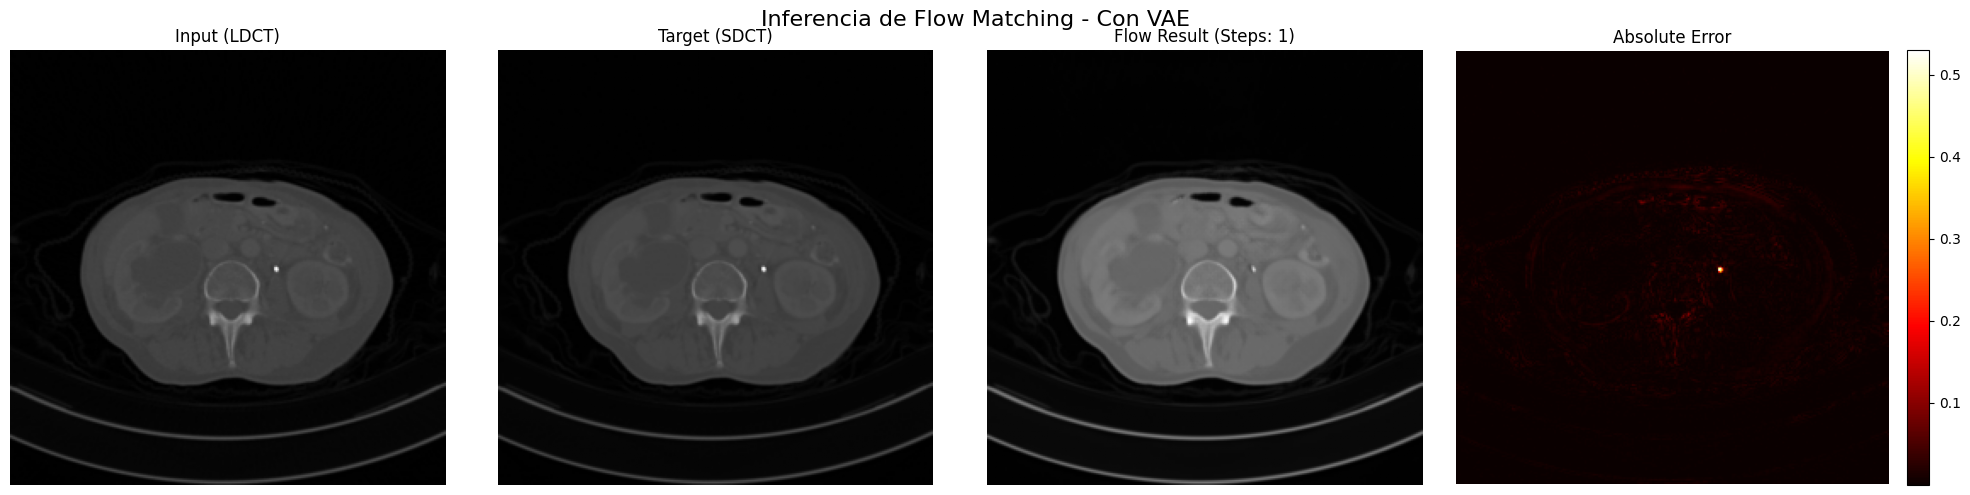

In [297]:

plot_flow_inference_vae(vae, model, data_item, device, 1)

PSNR: 57.49 dB, SSIM: 0.9986


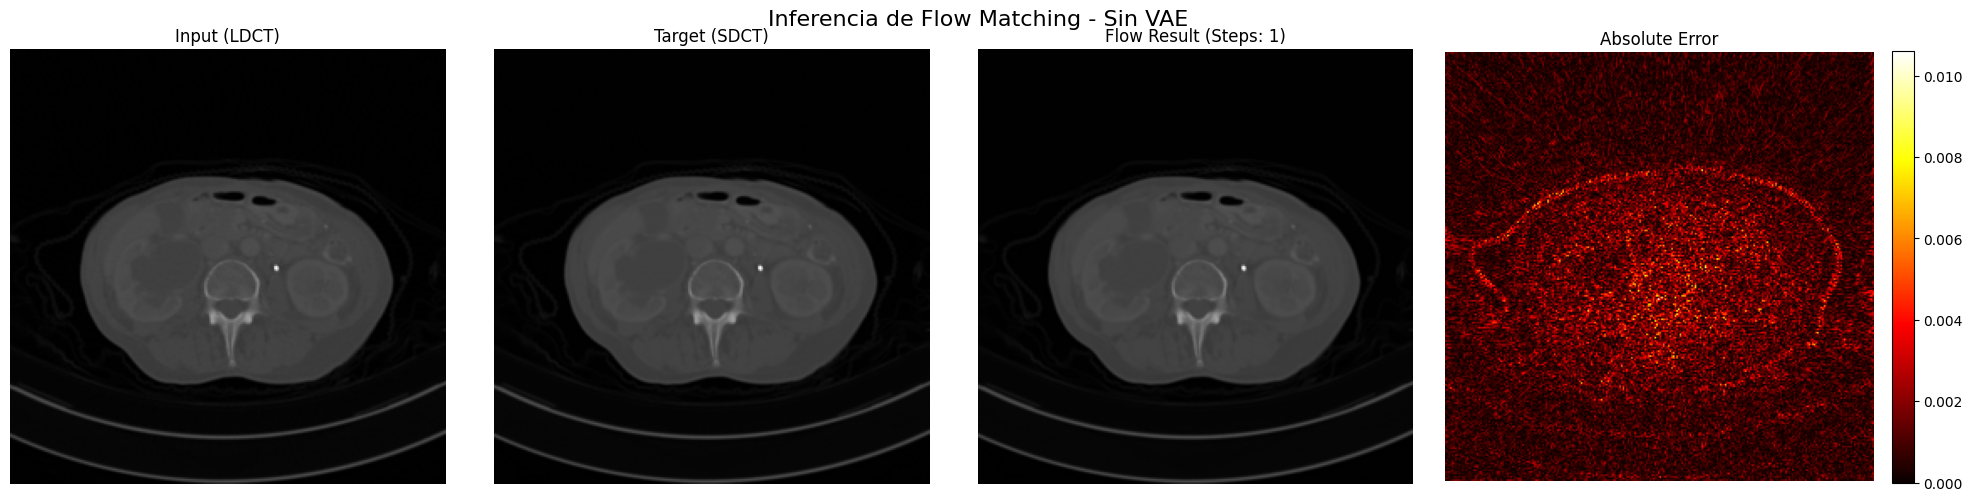

In [298]:

plot_flow_inference_model(model2, data_item, device, 1)

1 paso:
con vae 3m
sin vae 5m 47s
Promedio PSNR con VAE: 41.39 dB
Promedio SSIM con VAE: 0.9627
Promedio PSNR sin VAE: 50.98 dB
Promedio SSIM sin VAE: 0.9864

10 pasos:
con vae 12m 28s
sin vae 56m 16s
Promedio PSNR con VAE: 41.42 dB
Promedio SSIM con VAE: 0.9619
Promedio PSNR sin VAE: 50.20 dB
Promedio SSIM sin VAE: 0.9828

50 pasos:
con vae 54m 39s
sin vae 288min 29s
Promedio PSNR con VAE: 41.41 dB
Promedio SSIM con VAE: 0.9617
Promedio PSNR sin VAE: 50.01 dB
Promedio SSIM sin VAE: 0.9817